# Burgers’ equation and characteristic crossing

**Source:** Supplement to CompSci §6.2, which is a heading without exposition · [Source map](../docs/SOURCES.md) · [Course index](../README.md)

For smooth inviscid Burgers flow, $u_t+(u^2/2)_x=0$ implies $u_t+u u_x=0$. On a characteristic $X(t;a)=a+t u_0(a)$, $u=u_0(a)$. The map loses invertibility where $1+t u_0'(a)=0$, so $t_*=-1/\min u_0'$ when the minimum is negative. The resulting crossing diagram illustrates failure of the classical continuation, not a multi-valued physical solution.

A discontinuity in a weak solution satisfies Rankine–Hugoniot: $s=[F]/[u]=(u_L+u_R)/2$. For the convex flux $F(u)=u^2/2$, $u_L>u_R$ gives a compressive entropy shock; $u_L<u_R$ gives an expanding rarefaction instead.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.22,
                     "axes.spines.top": False, "axes.spines.right": False})
root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "01_Foundations").is_dir() and (p / "requirements.txt").is_file())
out = root / "assets" / "figures"
out.mkdir(parents=True, exist_ok=True)

def show(fig, name):
    fig.tight_layout()
    fig.savefig(out / (name + ".png"), dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

Matplotlib is building the font cache; this may take a moment.


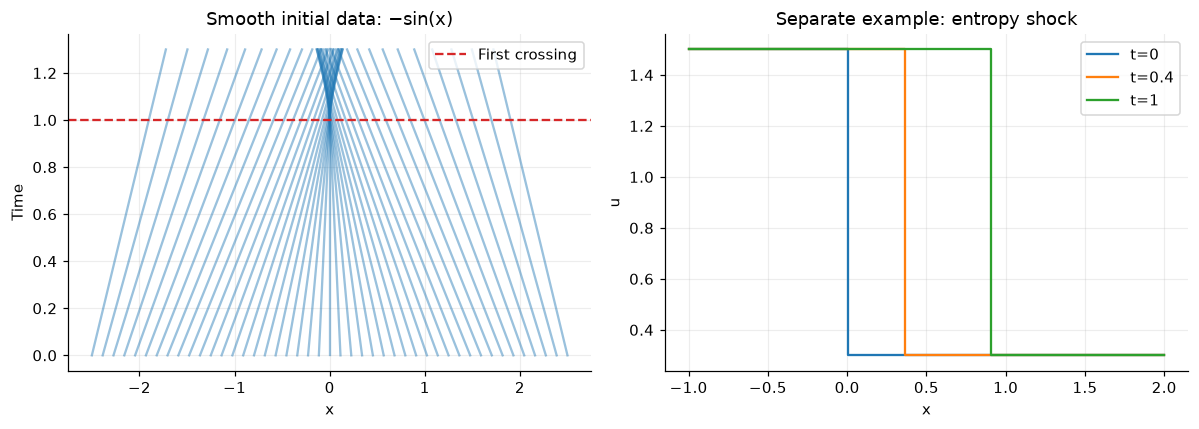

In [2]:
a=np.linspace(-2.5,2.5,45); t=np.linspace(0,1.3,160)
fig,ax=plt.subplots(1,2,figsize=(11,4))
for label in a: ax[0].plot(label-t*np.sin(label),t,color="C0",alpha=.45)
ax[0].axhline(1,color="C3",ls="--",label="First crossing")
ax[0].set(xlabel="x",ylabel="Time",title="Smooth initial data: −sin(x)"); ax[0].legend()
x=np.linspace(-1,2,401); left=1.5; right=.3; s=(left+right)/2
for ts in [0,.4,1]: ax[1].step(x,np.where(x<s*ts,left,right),where="post",label=f"t={ts}")
ax[1].set(xlabel="x",ylabel="u",title="Separate example: entropy shock"); ax[1].legend()
show(fig,"10-burgers")
assert np.min(1-.9*np.cos(a))>0 and np.min(1-1.1*np.cos(a))<0
assert np.isclose(s*(left-right),(left**2-right**2)/2) and right<s<left

## Worked exercise

**Find the shock speed for $u_L=2$, $u_R=0$.** The flux jump is 2 and the state jump is 2, giving speed 1. The characteristic extrapolation in the left plot is intentionally shown beyond its validity; predicting the post-shock sine profile would require an entropy solution.

## Additional experiment

Parametric profiles approaching shock onset.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True})
rng = np.random.default_rng(42)

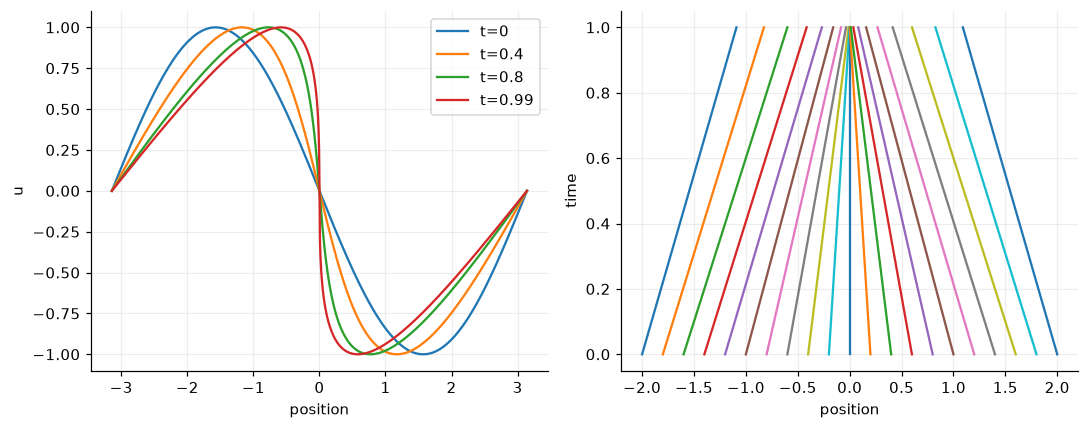

First crossing time = 1


In [4]:
xi=np.linspace(-np.pi,np.pi,501);u0=-np.sin(xi)
fig,ax=plt.subplots(1,2,figsize=(10,4))
for t in [0,.4,.8,.99]:ax[0].plot(xi+t*u0,u0,label=f"t={t}")
times=np.linspace(0,1,150)
for z in np.linspace(-2,2,21):ax[1].plot(z-times*np.sin(z),times)
ax[0].set(xlabel="position",ylabel="u");ax[0].legend();ax[1].set(xlabel="position",ylabel="time");plt.tight_layout();plt.show()
assert np.min(1-.99*np.cos(xi))>0
assert np.isclose(np.min(1-np.cos(xi)),0)
print("First crossing time = 1")

## Further practice

Derive t_s for u0=-A*sin(k*x), A,k>0. Explain why plotting crossed characteristics is not sufficient to compute a post-shock solution.

Record: prediction → observation → explanation. A successful assertion checks this example; it is not a general proof.